Configuration loaded.
Random State: 42
Test Size: 0.2
Final Threshold: 0.21
FN Cost: 5
FP Cost: 1

3. FINAL DATASET VERIFICATION
Dataset shape: (10000, 45)
Total missing values: 0
Duplicate rows: 0

Target distribution:
churn
0    8979
1    1021
Name: count, dtype: int64

Target percentage:
churn
0    89.79
1    10.21
Name: proportion, dtype: float64

Dataset verification: PASSED

4. FEATURE AND TARGET PREPARATION
Number of modelling features: 44
Target variable: churn

5. REPRODUCIBLE TRAIN/TEST SPLIT
Training observations: 8000
Testing observations: 2000

Training target distribution:
churn
0    7183
1     817
Name: count, dtype: int64

Testing target distribution:
churn
0    1796
1     204
Name: count, dtype: int64

Train/test split verification: PASSED

6. LOAD FINAL MODEL
Model loaded from: cost_sensitive_model_results/Best_Cost_Sensitive_XGBoost.pkl
Model type: <class 'imblearn.pipeline.Pipeline'>

Model pipeline steps:
 - preprocessing: ColumnTransformer
 - smote: SMOTE
 - model

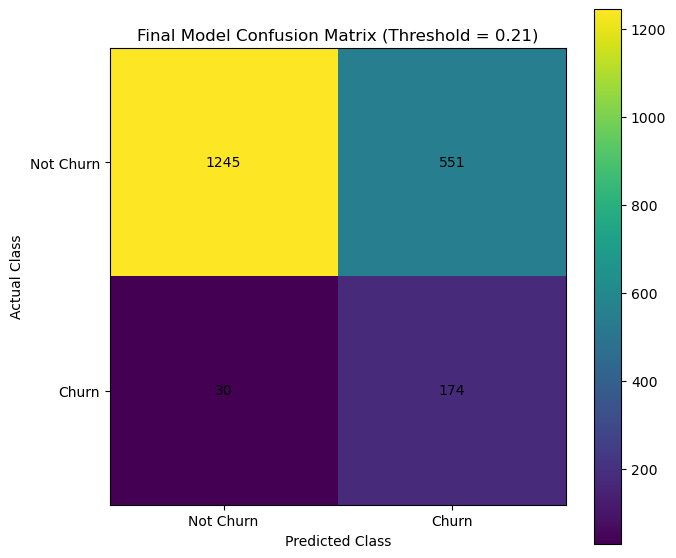


11. CLASSIFICATION REPORT
              precision    recall  f1-score   support

   Not Churn       0.98      0.69      0.81      1796
       Churn       0.24      0.85      0.37       204

    accuracy                           0.71      2000
   macro avg       0.61      0.77      0.59      2000
weighted avg       0.90      0.71      0.77      2000


12. ROC CURVE


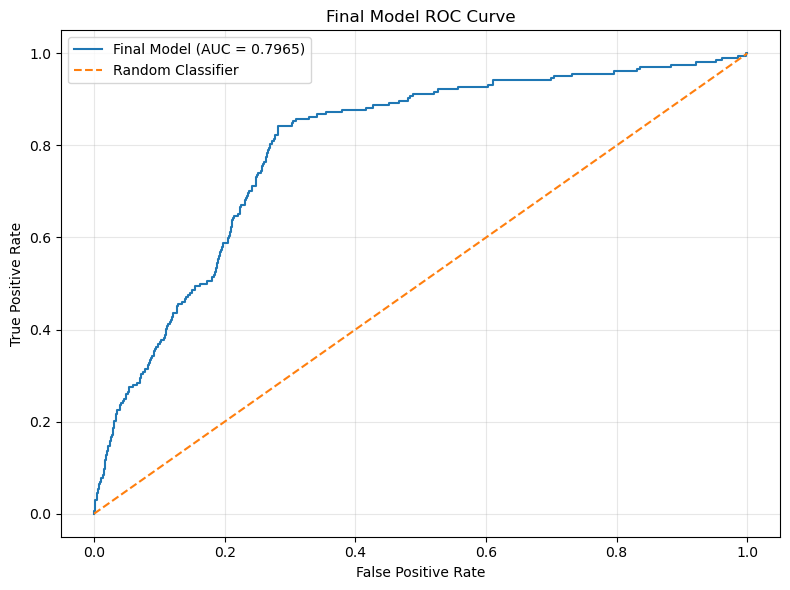


13. PRECISION-RECALL CURVE


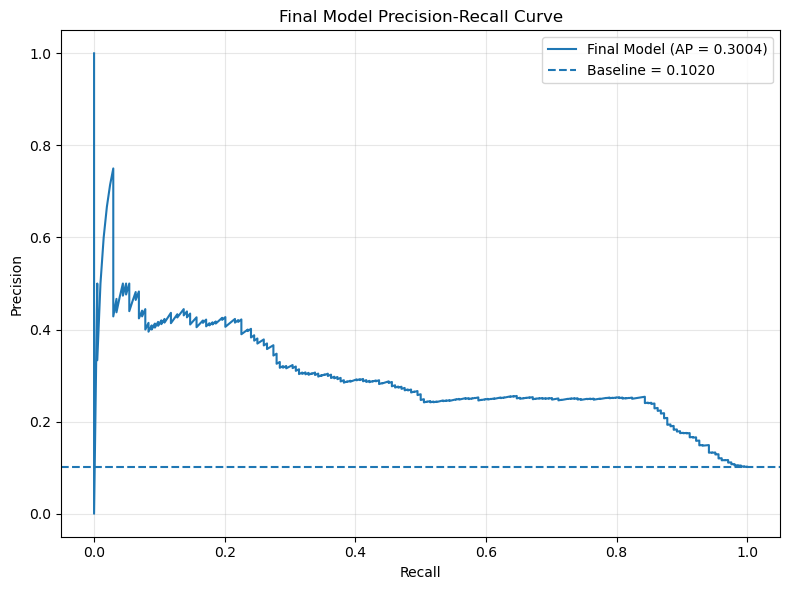


14. PROBABILITY CALIBRATION ASSESSMENT
   Mean_Predicted_Probability  Observed_Churn_Rate
0                       0.025             0.056179
1                       0.020             0.073648
2                       0.015             0.085044
3                       0.015             0.096259
4                       0.035             0.111011
5                       0.025             0.134338
6                       0.135             0.227390
7                       0.240             0.338230
8                       0.195             0.414474
9                       0.315             0.552978


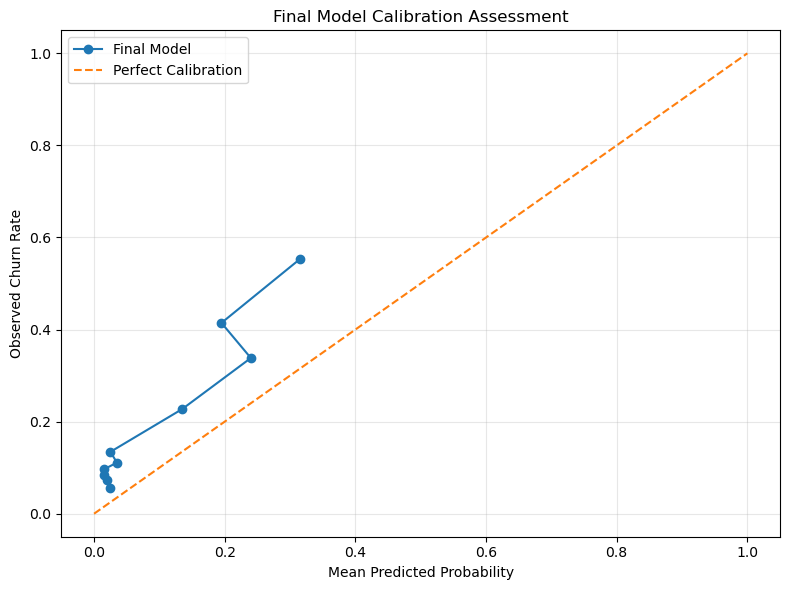


Brier Score: 0.0946

15. RISK DECILE VALIDATION
   risk_decile  customers  actual_churners  observed_churn_rate  \
0            1        200               63                0.315   
1            2        200               39                0.195   
2            3        200               48                0.240   
3            4        200               27                0.135   
4            5        200                5                0.025   
5            6        200                7                0.035   
6            7        200                3                0.015   
7            8        200                3                0.015   
8            9        200                4                0.020   
9           10        200                5                0.025   

   mean_predicted_probability  capture_rate      lift  
0                    0.552978      0.308824  3.088235  
1                    0.414474      0.191176  1.911765  
2                    0.338230      0.235294  

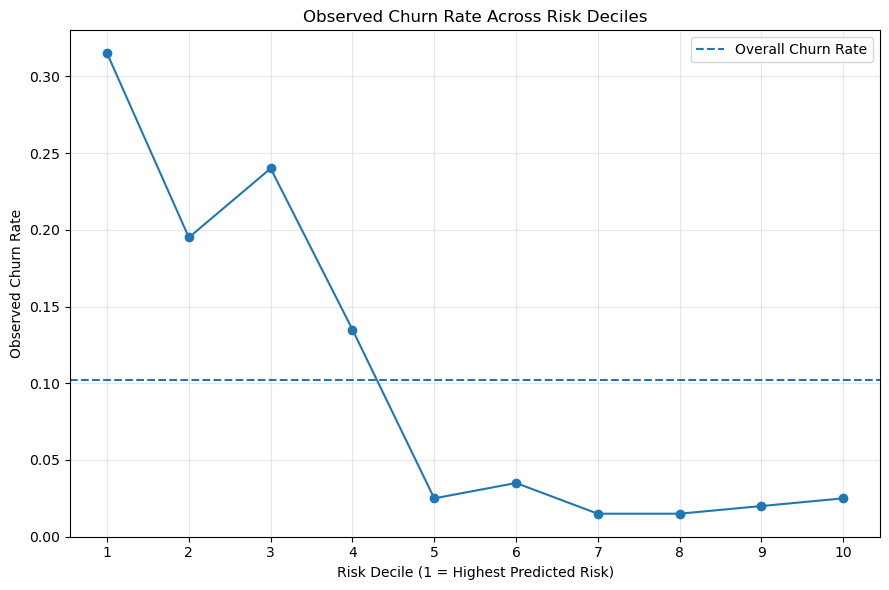


16. TOP-10% RETENTION TARGETING
                    Measure       Value
0        Customers Targeted  200.000000
1  Actual Churners Captured   63.000000
2                 Precision    0.315000
3              Capture Rate    0.308824
4       Observed Churn Rate    0.315000
5                      Lift    3.088235

17. FINAL ERROR ANALYSIS
  prediction_type  count  percentage
0   True Negative   1245       62.25
1  False Positive    551       27.55
2   True Positive    174        8.70
3  False Negative     30        1.50

18. BUSINESS COST SENSITIVITY
   False_Negative_Cost  False_Positive_Cost  False_Negatives  False_Positives  \
0                    2                    1               30              551   
1                    5                    1               30              551   
2                   10                    1               30              551   
3                   20                    1               30              551   

   Total_Business_Cost  
0             

In [1]:
# ============================================================
# Notebook 15: Final Evaluation & Reproducibility
# Hybrid Interpretable Machine Learning Model for
# Customer Churn Prediction with Real-World Validation
# ============================================================

# ============================================================
# 1. Libraries
# ============================================================

import os
import sys
import hashlib
import warnings
import platform
import importlib.metadata as metadata

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    balanced_accuracy_score,
    confusion_matrix,
    classification_report,
    brier_score_loss
)
from sklearn.calibration import calibration_curve

warnings.filterwarnings("ignore")


# ============================================================
# 2. Configuration
# ============================================================

RANDOM_STATE = 42
TEST_SIZE = 0.20

# Final decision threshold selected using training/CV results
FINAL_THRESHOLD = 0.21

# Hypothetical business-cost assumptions
FALSE_NEGATIVE_COST = 5
FALSE_POSITIVE_COST = 1

DATA_PATH = "customer_churn_feature_engineered.csv"

MODEL_PATH = (
    "cost_sensitive_model_results/"
    "Best_Cost_Sensitive_XGBoost.pkl"
)

# Notebook 14 outputs used for independent comparison
PREVIOUS_RESULTS_DIR = "real_world_validation_results"

OUTPUT_DIR = "final_evaluation_results"

os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Configuration loaded.")
print(f"Random State: {RANDOM_STATE}")
print(f"Test Size: {TEST_SIZE}")
print(f"Final Threshold: {FINAL_THRESHOLD}")
print(f"FN Cost: {FALSE_NEGATIVE_COST}")
print(f"FP Cost: {FALSE_POSITIVE_COST}")


# ============================================================
# 3. Final Dataset Verification
# ============================================================

print("\n" + "=" * 70)
print("3. FINAL DATASET VERIFICATION")
print("=" * 70)

Data_Df = pd.read_csv(DATA_PATH)

print(f"Dataset shape: {Data_Df.shape}")

missing_values = int(Data_Df.isnull().sum().sum())
duplicate_rows = int(Data_Df.duplicated().sum())

print(f"Total missing values: {missing_values}")
print(f"Duplicate rows: {duplicate_rows}")

print("\nTarget distribution:")
print(Data_Df["churn"].value_counts())

print("\nTarget percentage:")
print(
    (Data_Df["churn"].value_counts(normalize=True) * 100)
    .round(2)
)

# Expected dataset checks
assert Data_Df.shape == (10000, 45), (
    f"Unexpected dataset shape: {Data_Df.shape}"
)

assert missing_values == 0, (
    f"Dataset contains {missing_values} missing values."
)

assert duplicate_rows == 0, (
    f"Dataset contains {duplicate_rows} duplicate rows."
)

assert Data_Df["churn"].value_counts().to_dict() == {
    0: 8979,
    1: 1021
}, "Target distribution does not match the final dataset."

print("\nDataset verification: PASSED")


# ============================================================
# 4. Feature and Target Preparation
# ============================================================

print("\n" + "=" * 70)
print("4. FEATURE AND TARGET PREPARATION")
print("=" * 70)

X = Data_Df.drop(columns=["churn"]).copy()
y = Data_Df["churn"].copy()

# Customer ID is an identifier and was not used for modelling
if "customer_id" in X.columns:
    X = X.drop(columns=["customer_id"])

print(f"Number of modelling features: {X.shape[1]}")
print(f"Target variable: churn")

assert X.shape[1] == 44, (
    f"Expected 44 modelling features, found {X.shape[1]}"
)


# ============================================================
# 5. Reproduce Exact Train/Test Split
# ============================================================

print("\n" + "=" * 70)
print("5. REPRODUCIBLE TRAIN/TEST SPLIT")
print("=" * 70)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    stratify=y,
    random_state=RANDOM_STATE
)

print(f"Training observations: {len(X_train)}")
print(f"Testing observations: {len(X_test)}")

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

# Reproducibility checks
assert len(X_train) == 8000
assert len(X_test) == 2000

assert y_train.value_counts().to_dict() == {
    0: 7183,
    1: 817
}

assert y_test.value_counts().to_dict() == {
    0: 1796,
    1: 204
}

print("\nTrain/test split verification: PASSED")


# ============================================================
# 6. Load Final Model
# ============================================================

print("\n" + "=" * 70)
print("6. LOAD FINAL MODEL")
print("=" * 70)

assert os.path.exists(MODEL_PATH), (
    f"Final model not found: {MODEL_PATH}"
)

Final_Model = joblib.load(MODEL_PATH)

print(f"Model loaded from: {MODEL_PATH}")
print(f"Model type: {type(Final_Model)}")

print("\nModel pipeline steps:")

if hasattr(Final_Model, "named_steps"):
    for step_name, step_object in Final_Model.named_steps.items():
        print(
            f" - {step_name}: "
            f"{type(step_object).__name__}"
        )

print("\nFinal model loading: PASSED")


# ============================================================
# 7. Generate Final Predictions
# ============================================================

print("\n" + "=" * 70)
print("7. FINAL MODEL PREDICTIONS")
print("=" * 70)

# IMPORTANT:
# The saved pipeline performs preprocessing and SMOTE internally
# during training. No SMOTE is applied to the test set here.

Test_Probabilities = Final_Model.predict_proba(X_test)[:, 1]

Test_Predictions = (
    Test_Probabilities >= FINAL_THRESHOLD
).astype(int)

print(
    f"Minimum predicted probability: "
    f"{Test_Probabilities.min():.4f}"
)

print(
    f"Maximum predicted probability: "
    f"{Test_Probabilities.max():.4f}"
)

print(
    f"Mean predicted probability: "
    f"{Test_Probabilities.mean():.4f}"
)

print("\nPredicted classes:")
print(pd.Series(Test_Predictions).value_counts())


# ============================================================
# 8. Reproducibility / Deterministic Prediction Check
# ============================================================

print("\n" + "=" * 70)
print("8. DETERMINISTIC PREDICTION CHECK")
print("=" * 70)

# Run prediction a second time
Test_Probabilities_Repeat = (
    Final_Model.predict_proba(X_test)[:, 1]
)

Test_Predictions_Repeat = (
    Test_Probabilities_Repeat >= FINAL_THRESHOLD
).astype(int)

probability_reproducible = np.allclose(
    Test_Probabilities,
    Test_Probabilities_Repeat,
    rtol=1e-12,
    atol=1e-12
)

class_reproducible = np.array_equal(
    Test_Predictions,
    Test_Predictions_Repeat
)

print(
    f"Probability predictions reproducible: "
    f"{probability_reproducible}"
)

print(
    f"Class predictions reproducible: "
    f"{class_reproducible}"
)

assert probability_reproducible
assert class_reproducible

print("\nDeterministic prediction check: PASSED")


# ============================================================
# 9. Final Performance Evaluation
# ============================================================

print("\n" + "=" * 70)
print("9. FINAL PERFORMANCE EVALUATION")
print("=" * 70)

TN, FP, FN, TP = confusion_matrix(
    y_test,
    Test_Predictions
).ravel()

Accuracy = accuracy_score(
    y_test,
    Test_Predictions
)

Precision = precision_score(
    y_test,
    Test_Predictions,
    zero_division=0
)

Recall = recall_score(
    y_test,
    Test_Predictions,
    zero_division=0
)

F1 = f1_score(
    y_test,
    Test_Predictions,
    zero_division=0
)

ROC_AUC = roc_auc_score(
    y_test,
    Test_Probabilities
)

Average_Precision = average_precision_score(
    y_test,
    Test_Probabilities
)

Balanced_Accuracy = balanced_accuracy_score(
    y_test,
    Test_Predictions
)

Specificity = TN / (TN + FP)

Business_Cost = (
    FN * FALSE_NEGATIVE_COST
    + FP * FALSE_POSITIVE_COST
)

Brier_Score = brier_score_loss(
    y_test,
    Test_Probabilities
)

Final_Metrics = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC",
        "Average Precision",
        "Balanced Accuracy",
        "Specificity",
        "Brier Score",
        "True Negatives",
        "False Positives",
        "False Negatives",
        "True Positives",
        "Decision Threshold",
        "Business Cost"
    ],
    "Value": [
        Accuracy,
        Precision,
        Recall,
        F1,
        ROC_AUC,
        Average_Precision,
        Balanced_Accuracy,
        Specificity,
        Brier_Score,
        TN,
        FP,
        FN,
        TP,
        FINAL_THRESHOLD,
        Business_Cost
    ]
})

print(
    Final_Metrics.to_string(index=False)
)

Final_Metrics.to_csv(
    f"{OUTPUT_DIR}/Final_Model_Performance.csv",
    index=False
)


# ============================================================
# 10. Confusion Matrix
# ============================================================

print("\n" + "=" * 70)
print("10. CONFUSION MATRIX")
print("=" * 70)

CM = confusion_matrix(
    y_test,
    Test_Predictions
)

CM_Df = pd.DataFrame(
    CM,
    index=["Actual Not Churn", "Actual Churn"],
    columns=["Predicted Not Churn", "Predicted Churn"]
)

print(CM_Df)

CM_Df.to_csv(
    f"{OUTPUT_DIR}/Final_Confusion_Matrix.csv"
)

plt.figure(figsize=(7, 6))

plt.imshow(CM)

plt.title(
    f"Final Model Confusion Matrix "
    f"(Threshold = {FINAL_THRESHOLD})"
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.xticks(
    [0, 1],
    ["Not Churn", "Churn"]
)

plt.yticks(
    [0, 1],
    ["Not Churn", "Churn"]
)

for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            CM[i, j],
            ha="center",
            va="center"
        )

plt.colorbar()
plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/Final_Confusion_Matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 11. Classification Report
# ============================================================

print("\n" + "=" * 70)
print("11. CLASSIFICATION REPORT")
print("=" * 70)

Classification_Report = classification_report(
    y_test,
    Test_Predictions,
    target_names=["Not Churn", "Churn"],
    zero_division=0
)

print(Classification_Report)

with open(
    f"{OUTPUT_DIR}/Final_Classification_Report.txt",
    "w"
) as file:

    file.write(Classification_Report)


# ============================================================
# 12. ROC Curve
# ============================================================

print("\n" + "=" * 70)
print("12. ROC CURVE")
print("=" * 70)

from sklearn.metrics import roc_curve

FPR, TPR, ROC_Thresholds = roc_curve(
    y_test,
    Test_Probabilities
)

plt.figure(figsize=(8, 6))

plt.plot(
    FPR,
    TPR,
    label=f"Final Model (AUC = {ROC_AUC:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Final Model ROC Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/Final_ROC_Curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 13. Precision-Recall Curve
# ============================================================

print("\n" + "=" * 70)
print("13. PRECISION-RECALL CURVE")
print("=" * 70)

from sklearn.metrics import precision_recall_curve

PR_Precision, PR_Recall, PR_Thresholds = (
    precision_recall_curve(
        y_test,
        Test_Probabilities
    )
)

plt.figure(figsize=(8, 6))

plt.plot(
    PR_Recall,
    PR_Precision,
    label=f"Final Model (AP = {Average_Precision:.4f})"
)

plt.axhline(
    y=y_test.mean(),
    linestyle="--",
    label=f"Baseline = {y_test.mean():.4f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Final Model Precision-Recall Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/Final_Precision_Recall_Curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 14. Probability Calibration Assessment
# ============================================================

print("\n" + "=" * 70)
print("14. PROBABILITY CALIBRATION ASSESSMENT")
print("=" * 70)

# Calibration is assessed only.
# No calibration model is fitted on the test set.

Calibration_Probabilities, Calibration_Observed = (
    calibration_curve(
        y_test,
        Test_Probabilities,
        n_bins=10,
        strategy="quantile"
    )
)

Calibration_Df = pd.DataFrame({
    "Mean_Predicted_Probability": Calibration_Probabilities,
    "Observed_Churn_Rate": Calibration_Observed
})

print(Calibration_Df)

Calibration_Df.to_csv(
    f"{OUTPUT_DIR}/Calibration_Assessment.csv",
    index=False
)

plt.figure(figsize=(8, 6))

plt.plot(
    Calibration_Probabilities,
    Calibration_Observed,
    marker="o",
    label="Final Model"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect Calibration"
)

plt.xlabel("Mean Predicted Probability")
plt.ylabel("Observed Churn Rate")
plt.title("Final Model Calibration Assessment")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/Final_Calibration_Curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    f"\nBrier Score: {Brier_Score:.4f}"
)


# ============================================================
# 15. Risk Decile Validation
# ============================================================

print("\n" + "=" * 70)
print("15. RISK DECILE VALIDATION")
print("=" * 70)

Risk_Df = pd.DataFrame({
    "actual_churn": y_test.to_numpy(),
    "predicted_probability": Test_Probabilities
})

# Rank customers from highest to lowest predicted probability
Risk_Df = Risk_Df.sort_values(
    "predicted_probability",
    ascending=False
).reset_index(drop=True)

Risk_Df["risk_decile"] = pd.qcut(
    Risk_Df.index,
    q=10,
    labels=False
) + 1

Risk_Decile_Summary = (
    Risk_Df
    .groupby("risk_decile")
    .agg(
        customers=("actual_churn", "size"),
        actual_churners=("actual_churn", "sum"),
        observed_churn_rate=("actual_churn", "mean"),
        mean_predicted_probability=(
            "predicted_probability",
            "mean"
        )
    )
    .reset_index()
)

Risk_Decile_Summary["capture_rate"] = (
    Risk_Decile_Summary["actual_churners"]
    / y_test.sum()
)

Risk_Decile_Summary["lift"] = (
    Risk_Decile_Summary["observed_churn_rate"]
    / y_test.mean()
)

print(Risk_Decile_Summary)

Risk_Decile_Summary.to_csv(
    f"{OUTPUT_DIR}/Final_Risk_Decile_Validation.csv",
    index=False
)

plt.figure(figsize=(9, 6))

plt.plot(
    Risk_Decile_Summary["risk_decile"],
    Risk_Decile_Summary["observed_churn_rate"],
    marker="o"
)

plt.axhline(
    y=y_test.mean(),
    linestyle="--",
    label="Overall Churn Rate"
)

plt.xlabel(
    "Risk Decile "
    "(1 = Highest Predicted Risk)"
)

plt.ylabel("Observed Churn Rate")
plt.title("Observed Churn Rate Across Risk Deciles")
plt.xticks(range(1, 11))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/Final_Risk_Decile_Validation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 16. Top-10% Retention Targeting Validation
# ============================================================

print("\n" + "=" * 70)
print("16. TOP-10% RETENTION TARGETING")
print("=" * 70)

Top10_Count = int(len(X_test) * 0.10)

Top10 = Risk_Df.head(Top10_Count)

Top10_Actual_Churners = int(
    Top10["actual_churn"].sum()
)

Top10_Precision = (
    Top10_Actual_Churners
    / len(Top10)
)

Top10_Capture = (
    Top10_Actual_Churners
    / y_test.sum()
)

Top10_Observed_Churn = (
    Top10["actual_churn"].mean()
)

Top10_Lift = (
    Top10_Observed_Churn
    / y_test.mean()
)

Top10_Summary = pd.DataFrame({
    "Measure": [
        "Customers Targeted",
        "Actual Churners Captured",
        "Precision",
        "Capture Rate",
        "Observed Churn Rate",
        "Lift"
    ],
    "Value": [
        len(Top10),
        Top10_Actual_Churners,
        Top10_Precision,
        Top10_Capture,
        Top10_Observed_Churn,
        Top10_Lift
    ]
})

print(Top10_Summary)

Top10_Summary.to_csv(
    f"{OUTPUT_DIR}/Final_Top_10_Percent_Targeting.csv",
    index=False
)


# ============================================================
# 17. Final Error Analysis
# ============================================================

print("\n" + "=" * 70)
print("17. FINAL ERROR ANALYSIS")
print("=" * 70)

Error_Df = pd.DataFrame({
    "actual_churn": y_test.to_numpy(),
    "predicted_churn": Test_Predictions,
    "predicted_probability": Test_Probabilities
})

def classify_prediction(row):

    if row["actual_churn"] == 1 and row["predicted_churn"] == 1:
        return "True Positive"

    elif row["actual_churn"] == 0 and row["predicted_churn"] == 0:
        return "True Negative"

    elif row["actual_churn"] == 0 and row["predicted_churn"] == 1:
        return "False Positive"

    else:
        return "False Negative"


Error_Df["prediction_type"] = Error_Df.apply(
    classify_prediction,
    axis=1
)

Error_Summary = (
    Error_Df["prediction_type"]
    .value_counts()
    .rename_axis("prediction_type")
    .reset_index(name="count")
)

Error_Summary["percentage"] = (
    Error_Summary["count"]
    / len(Error_Df)
    * 100
)

print(Error_Summary)

Error_Summary.to_csv(
    f"{OUTPUT_DIR}/Final_Error_Analysis.csv",
    index=False
)


# ============================================================
# 18. Business Cost Sensitivity
# ============================================================

print("\n" + "=" * 70)
print("18. BUSINESS COST SENSITIVITY")
print("=" * 70)

FN_Cost_Scenarios = [2, 5, 10, 20]

Business_Cost_Results = []

for fn_cost in FN_Cost_Scenarios:

    total_cost = (
        FN * fn_cost
        + FP * FALSE_POSITIVE_COST
    )

    Business_Cost_Results.append({
        "False_Negative_Cost": fn_cost,
        "False_Positive_Cost": FALSE_POSITIVE_COST,
        "False_Negatives": FN,
        "False_Positives": FP,
        "Total_Business_Cost": total_cost
    })

Business_Cost_Df = pd.DataFrame(
    Business_Cost_Results
)

print(Business_Cost_Df)

Business_Cost_Df.to_csv(
    f"{OUTPUT_DIR}/Final_Business_Cost_Sensitivity.csv",
    index=False
)


# ============================================================
# 19. Compare With Notebook 14 Results
# ============================================================

print("\n" + "=" * 70)
print("19. CROSS-NOTEBOOK REPRODUCIBILITY CHECK")
print("=" * 70)

Previous_Metrics_Path = (
    f"{PREVIOUS_RESULTS_DIR}/"
    "Final_Real_World_Validation_Summary.csv"
)

if os.path.exists(Previous_Metrics_Path):

    Previous_Metrics = pd.read_csv(
        Previous_Metrics_Path
    )

    print("Notebook 14 summary found.")

    print("\nNotebook 14 summary:")
    print(Previous_Metrics)

    # Convert previous summary to dictionary
    Previous_Metrics_Dict = dict(
        zip(
            Previous_Metrics.iloc[:, 0],
            Previous_Metrics.iloc[:, 1]
        )
    )

    Comparison_Results = []

    Metrics_To_Compare = [
        ("Accuracy", Accuracy),
        ("Precision", Precision),
        ("Recall", Recall),
        ("F1-Score", F1),
        ("ROC-AUC", ROC_AUC),
        ("Average Precision", Average_Precision),
        ("Balanced Accuracy", Balanced_Accuracy),
        ("Specificity", Specificity),
        ("True Negatives", TN),
        ("False Positives", FP),
        ("False Negatives", FN),
        ("True Positives", TP)
    ]

    for metric_name, current_value in Metrics_To_Compare:

        if metric_name in Previous_Metrics_Dict:

            previous_value = (
                Previous_Metrics_Dict[metric_name]
            )

            difference = (
                current_value - previous_value
            )

            matches = np.isclose(
                current_value,
                previous_value,
                rtol=1e-8,
                atol=1e-8
            )

            Comparison_Results.append({
                "Metric": metric_name,
                "Notebook_14_Value": previous_value,
                "Notebook_15_Value": current_value,
                "Difference": difference,
                "Reproducible": matches
            })

    Reproducibility_Comparison = pd.DataFrame(
        Comparison_Results
    )

    print("\nCross-notebook comparison:")
    print(
        Reproducibility_Comparison.to_string(
            index=False
        )
    )

    Reproducibility_Comparison.to_csv(
        f"{OUTPUT_DIR}/"
        "Notebook_14_vs_Notebook_15_Reproducibility.csv",
        index=False
    )

    if not Reproducibility_Comparison.empty:

        assert (
            Reproducibility_Comparison["Reproducible"]
            .all()
        )

        print(
            "\nNotebook 14 vs Notebook 15: PASSED"
        )

else:

    print(
        "Notebook 14 summary file was not found."
    )

    print(
        "Independent final evaluation will still be used."
    )


# ============================================================
# 20. Model and Dataset File Hashes
# ============================================================

print("\n" + "=" * 70)
print("20. FILE INTEGRITY HASHES")
print("=" * 70)

def calculate_sha256(file_path):

    sha256_hash = hashlib.sha256()

    with open(file_path, "rb") as file:

        for chunk in iter(
            lambda: file.read(8192),
            b""
        ):
            sha256_hash.update(chunk)

    return sha256_hash.hexdigest()


Dataset_Hash = calculate_sha256(
    DATA_PATH
)

Model_Hash = calculate_sha256(
    MODEL_PATH
)

File_Integrity = pd.DataFrame({
    "File": [
        DATA_PATH,
        MODEL_PATH
    ],
    "SHA256": [
        Dataset_Hash,
        Model_Hash
    ]
})

print(File_Integrity)

File_Integrity.to_csv(
    f"{OUTPUT_DIR}/File_Integrity_SHA256.csv",
    index=False
)


# ============================================================
# 21. Software Environment
# ============================================================

print("\n" + "=" * 70)
print("21. SOFTWARE ENVIRONMENT")
print("=" * 70)

Package_Names = [
    "numpy",
    "pandas",
    "scikit-learn",
    "imbalanced-learn",
    "xgboost",
    "shap",
    "joblib",
    "matplotlib"
]

Environment_Information = []

for package in Package_Names:

    try:
        version = metadata.version(package)

    except metadata.PackageNotFoundError:
        version = "Not installed"

    Environment_Information.append({
        "Package": package,
        "Version": version
    })

Environment_Df = pd.DataFrame(
    Environment_Information
)

print(Environment_Df)

Environment_Df.to_csv(
    f"{OUTPUT_DIR}/Software_Environment.csv",
    index=False
)


# ============================================================
# 22. Python and System Information
# ============================================================

System_Information = pd.DataFrame({
    "Parameter": [
        "Python Version",
        "Operating System",
        "Platform",
        "Random State",
        "Test Size",
        "Final Threshold",
        "FN Cost Assumption",
        "FP Cost Assumption"
    ],
    "Value": [
        sys.version,
        platform.system(),
        platform.platform(),
        RANDOM_STATE,
        TEST_SIZE,
        FINAL_THRESHOLD,
        FALSE_NEGATIVE_COST,
        FALSE_POSITIVE_COST
    ]
})

print("\nSystem information:")
print(System_Information)

System_Information.to_csv(
    f"{OUTPUT_DIR}/System_Information.csv",
    index=False
)


# ============================================================
# 23. Final Framework Evidence Summary
# ============================================================

print("\n" + "=" * 70)
print("23. FINAL FRAMEWORK EVIDENCE SUMMARY")
print("=" * 70)

Framework_Evidence = pd.DataFrame({
    "Evaluation_Area": [
        "Dataset integrity",
        "Class imbalance",
        "Reproducible train/test split",
        "Final model reproducibility",
        "Threshold reproducibility",
        "Discrimination",
        "Churn recall",
        "Balanced classification",
        "Risk ranking",
        "Top-10% retention targeting",
        "Business cost analysis",
        "Model interpretability",
        "External validation"
    ],

    "Evidence": [
        "10,000 observations, 45 columns, zero missing values and zero duplicate rows",
        "10.21% churn and 89.79% non-churn",
        "Stratified 80/20 split using random state 42",
        "Saved cost-sensitive XGBoost pipeline reproduced identical predictions",
        f"Threshold fixed at {FINAL_THRESHOLD} from training/CV optimisation",
        f"ROC-AUC = {ROC_AUC:.4f}",
        f"Recall = {Recall:.4f}",
        f"Balanced Accuracy = {Balanced_Accuracy:.4f}",
        f"Top risk decile lift = {Top10_Lift:.3f}",
        f"{Top10_Actual_Churners} of {int(y_test.sum())} churners captured in top 10%",
        f"Business cost = {Business_Cost}",
        "SHAP analysis completed in Notebook 14 for the XGBoost component",
        "Not performed; validation uses an unseen hold-out test set from the same dataset"
    ]
})

print(
    Framework_Evidence.to_string(index=False)
)

Framework_Evidence.to_csv(
    f"{OUTPUT_DIR}/Final_Framework_Evidence_Summary.csv",
    index=False
)


# ============================================================
# 24. Final Limitations
# ============================================================

print("\n" + "=" * 70)
print("24. FINAL LIMITATIONS")
print("=" * 70)

Limitations = pd.DataFrame({
    "Limitation": [
        "Single dataset",
        "No external validation",
        "Class imbalance",
        "Moderate precision",
        "False positives",
        "Hypothetical business costs",
        "Probability calibration",
        "SHAP scope",
        "Feature redundancy",
        "No causal interpretation",
        "Global hybrid architecture"
    ],

    "Description": [
        "The framework was evaluated using one customer churn dataset.",
        "The final test set is an unseen hold-out sample rather than an independent external dataset.",
        "The original dataset contains substantially fewer churn cases than non-churn cases.",
        "At the selected threshold, precision remains limited, resulting in a substantial number of false-positive retention targets.",
        "The model identifies many non-churn customers as potential churners when prioritising high recall.",
        "False-negative and false-positive costs were methodological assumptions rather than verified organisational financial values.",
        "Predicted probabilities should be interpreted cautiously because the model was trained using SMOTE and cost-sensitive learning.",
        "SHAP explanations describe the trained cost-sensitive XGBoost component rather than the entire weighted hybrid probability blend.",
        "Several engineered variables are mathematically related to original variables, including CSAT-derived features.",
        "Model associations should not be interpreted as evidence that a feature causes customer churn.",
        "The hybrid model is a global weighted probability blend rather than an instance-dependent gating mechanism."
    ]
})

print(
    Limitations.to_string(index=False)
)

Limitations.to_csv(
    f"{OUTPUT_DIR}/Final_Limitations.csv",
    index=False
)


# ============================================================
# 25. Final Quality Checks
# ============================================================

print("\n" + "=" * 70)
print("25. FINAL QUALITY CHECKS")
print("=" * 70)

Quality_Checks = {
    "Dataset shape correct":
        Data_Df.shape == (10000, 45),

    "No missing values":
        missing_values == 0,

    "No duplicate rows":
        duplicate_rows == 0,

    "Correct feature count":
        X.shape[1] == 44,

    "Correct train size":
        len(X_train) == 8000,

    "Correct test size":
        len(X_test) == 2000,

    "Correct test churn count":
        int(y_test.sum()) == 204,

    "Correct threshold":
        FINAL_THRESHOLD == 0.21,

    "Deterministic probabilities":
        probability_reproducible,

    "Deterministic classes":
        class_reproducible,

    "Valid ROC-AUC":
        0 <= ROC_AUC <= 1,

    "Valid precision":
        0 <= Precision <= 1,

    "Valid recall":
        0 <= Recall <= 1,

    "Valid F1":
        0 <= F1 <= 1,

    "Valid specificity":
        0 <= Specificity <= 1,

    "Confusion matrix totals correct":
        TN + FP + FN + TP == len(y_test)
}

Quality_Check_Df = pd.DataFrame({
    "Quality_Check": list(Quality_Checks.keys()),
    "Passed": list(Quality_Checks.values())
})

print(Quality_Check_Df.to_string(index=False))

assert all(Quality_Checks.values())

Quality_Check_Df.to_csv(
    f"{OUTPUT_DIR}/Final_Quality_Checks.csv",
    index=False
)

print("\nALL QUALITY CHECKS PASSED.")


# ============================================================
# 26. Final Results Summary
# ============================================================

print("\n" + "=" * 70)
print("26. FINAL RESULTS SUMMARY")
print("=" * 70)

Final_Summary = pd.DataFrame({
    "Measure": [
        "Dataset Size",
        "Test Set Size",
        "Test Churn Cases",
        "Decision Threshold",
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC",
        "Average Precision",
        "Balanced Accuracy",
        "Specificity",
        "Brier Score",
        "True Positives",
        "False Positives",
        "False Negatives",
        "True Negatives",
        "Business Cost",
        "Top-10% Capture Rate",
        "Top-10% Lift"
    ],

    "Value": [
        f"{Data_Df.shape[0]} observations",
        len(X_test),
        int(y_test.sum()),
        FINAL_THRESHOLD,
        round(Accuracy, 4),
        round(Precision, 4),
        round(Recall, 4),
        round(F1, 4),
        round(ROC_AUC, 4),
        round(Average_Precision, 4),
        round(Balanced_Accuracy, 4),
        round(Specificity, 4),
        round(Brier_Score, 4),
        TP,
        FP,
        FN,
        TN,
        Business_Cost,
        round(Top10_Capture, 4),
        round(Top10_Lift, 4)
    ]
})

print(
    Final_Summary.to_string(index=False)
)

Final_Summary.to_csv(
    f"{OUTPUT_DIR}/Final_Evaluation_Summary.csv",
    index=False
)


# ============================================================
# 27. Save Final Test Predictions
# ============================================================

Final_Test_Predictions = pd.DataFrame({
    "actual_churn": y_test.to_numpy(),
    "predicted_probability": Test_Probabilities,
    "predicted_churn": Test_Predictions,
    "decision_threshold": FINAL_THRESHOLD
})

Final_Test_Predictions.to_csv(
    f"{OUTPUT_DIR}/Final_Test_Predictions.csv",
    index=False
)

print(
    "\nFinal test predictions saved."
)


# ============================================================
# 28. Final Reproducibility Report
# ============================================================

Reproducibility_Report = pd.DataFrame({
    "Component": [
        "Dataset",
        "Model",
        "Train/Test Split",
        "Random State",
        "Decision Threshold",
        "Test Set",
        "Prediction Reproducibility",
        "Previous Notebook Comparison",
        "File Integrity",
        "Environment Documentation",
        "Final Quality Checks"
    ],

    "Status": [
        "Verified",
        "Loaded successfully",
        "Reproduced",
        RANDOM_STATE,
        FINAL_THRESHOLD,
        "2,000 observations",
        "Passed",
        "Compared against Notebook 14",
        "SHA-256 recorded",
        "Python and package versions recorded",
        "All passed"
    ]
})

print("\nReproducibility report:")
print(
    Reproducibility_Report.to_string(index=False)
)

Reproducibility_Report.to_csv(
    f"{OUTPUT_DIR}/Final_Reproducibility_Report.csv",
    index=False
)


# ============================================================
# 29. Export List
# ============================================================

print("\n" + "=" * 70)
print("29. GENERATED OUTPUTS")
print("=" * 70)

Generated_Files = sorted(
    os.listdir(OUTPUT_DIR)
)

for file_name in Generated_Files:
    print(f" - {file_name}")

print(
    f"\nTotal output files generated: "
    f"{len(Generated_Files)}"
)


# ============================================================
# 30. FINAL NOTEBOOK CONCLUSION
# ============================================================

print("\n" + "=" * 70)
print("30. NOTEBOOK 15 CONCLUSION")
print("=" * 70)

print(
    f"""
The final customer churn prediction framework was independently
evaluated on the unseen test set using the fixed decision threshold
of {FINAL_THRESHOLD}.

Final performance:
- Accuracy: {Accuracy:.4f}
- Precision: {Precision:.4f}
- Recall: {Recall:.4f}
- F1-Score: {F1:.4f}
- ROC-AUC: {ROC_AUC:.4f}
- Average Precision: {Average_Precision:.4f}
- Balanced Accuracy: {Balanced_Accuracy:.4f}
- Specificity: {Specificity:.4f}

Confusion matrix:
- True Positives: {TP}
- False Positives: {FP}
- False Negatives: {FN}
- True Negatives: {TN}

The saved model produced deterministic predictions when evaluated
repeatedly using the same data and configuration.

The final framework therefore provides a reproducible,
threshold-controlled and business-oriented churn prediction process.
However, the evaluation remains internal to the available dataset,
and external validation, probability calibration and broader
generalisability remain areas for future research.
"""
)

print("\nNotebook 15 completed successfully.")